# Credit Card Transactions Fraud Detection · 05 Evaluation & Explainability

# Aim, Objective, and Motivation
- **Aim:** <u>measure</u> the final model honestly on unseen future data and <u>explain</u> its decisions.
- **Objective:** choose a business threshold on validation, evaluate **once** on the test period (Jun – Dec 2020),
  then open the black box with SHAP and analyse the errors.
- **Motivation:** a fraud model is only useful if its alerts are worth investigating and analysts can understand *why*
  a transaction was flagged.

# Outlines
1. Load model & data
2. Choose the decision threshold (validation)
3. Final model: refit on train + valid
4. Test performance
5. Business impact in dollars
6. Calibration
7. Global explainability: feature importance & SHAP
8. Local explainability: why was this transaction flagged?
9. Error analysis
10. Stability over time
11. Summary

In [1]:
# ---------------------------------------------------------------- Imports
import sys
import json
import warnings
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
import shap
from sklearn.metrics import average_precision_score, brier_score_loss

from src.config import COLORS, LABELS, MODELS_DIR, ROOT, RANDOM_STATE, TARGET
from src.data import load_processed
from src.evaluate import (score, recall_at_precision, fraud_cost, best_cost_threshold, best_f1_threshold,
                          plot_pr_roc, plot_confusion)
from src.features import FEATURES
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
REVIEW_COST = 10.0                    # $ to investigate one alert (analyst time, customer call)
MIN_PRECISION = 0.90
SHAP_SAMPLE = 20_000                  # test rows used for SHAP (all frauds + random legit)
AMOUNT_BINS = [0, 50, 200, 500, 800, 1000, 1500, 30000]
CALIBRATION_BINS = [0, 0.001, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]  # fixed risk bands
REPORTS_DIR = ROOT / "reports"
BEST = json.load(open(REPORTS_DIR / "best_model.json"))

set_style()

# [1/11] Load model & data
> **Objective:** <u>load</u> the tuned LightGBM (trained on train only) and all three splits.

In [2]:
splits = {s: load_processed(s) for s in ["train", "valid", "test"]}
for d in splits.values():
    d["category"] = pd.Categorical(d["category"], categories=BEST["categories"])
train, valid, test = splits["train"], splits["valid"], splits["test"]
model_train_only = joblib.load(MODELS_DIR / "lgbm_tuned.joblib")

In [3]:
print({s: d.shape for s, d in splits.items()})
BEST["params"]

{'train': (1070966, 23), 'valid': (225709, 23), 'test': (555719, 23)}


{'n_estimators': 1109,
 'learning_rate': 0.03632553166214022,
 'num_leaves': 20,
 'subsample': 0.9989791105691248,
 'subsample_freq': 1,
 'colsample_bytree': 0.8559082548800234,
 'random_state': 42,
 'n_jobs': -1,
 'verbose': -1,
 'min_child_samples': 205,
 'reg_alpha': 0.2812113622782828,
 'reg_lambda': 0.287814957440709}

# [2/11] Choose the decision threshold (validation)
> **Question:** above which fraud probability should we raise an alert?
>
> The model outputs $\hat{p} = P(\text{fraud} \mid x)$; we alert if $\hat{p} \ge \tau$. Two ways to pick $\tau$:
> - **F1-optimal:** maximise $F_1(\tau)$ — treats precision and recall as equally important.
> - **Cost-optimal (business):** every alert costs \$10 to review, every missed fraud costs its amount:
>   $\text{Cost}(\tau) = 10 \cdot \#\{\hat{p} \ge \tau\} + \sum_{i:\ y_i = 1,\ \hat{p}_i < \tau} \text{amount}_i$
>
> $\tau$ is chosen on **validation** (never on test).

In [4]:
p_valid = model_train_only.predict_proba(valid[FEATURES])[:, 1]
tau_cost, cost_curve = best_cost_threshold(valid[TARGET], p_valid, valid["amount"], REVIEW_COST)
tau_f1 = best_f1_threshold(valid[TARGET], p_valid)
no_model_cost = valid.loc[valid[TARGET] == 1, "amount"].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(cost_curve["threshold"], cost_curve["cost"] / 1e3, color=COLORS[0])
ax.axvline(tau_cost, color=COLORS[1], ls="--", label=f"cost-optimal τ = {tau_cost:.2f}")
ax.axvline(tau_f1, color="black", ls=":", label=f"F1-optimal τ = {tau_f1:.2f}")
ax.set(xlabel="threshold τ", ylabel="cost (thousand $)", title="Validation cost vs threshold")
ax.legend()
savefig(fig, "05_cost_threshold")
plt.close(fig)

In [5]:
pd.DataFrame([
    {"threshold": "no model (miss everything)", "cost_$": no_model_cost},
    {"threshold": f"F1-optimal τ={tau_f1:.2f}", "cost_$": fraud_cost(valid[TARGET], p_valid, valid["amount"], tau_f1, REVIEW_COST)},
    {"threshold": f"cost-optimal τ={tau_cost:.2f}", "cost_$": cost_curve["cost"].min()},
]).round(0)

,threshold,cost_$
0,no model (miss everything),671623.0
1,F1-optimal τ=0.37,30047.0
2,cost-optimal τ=0.02,18168.0


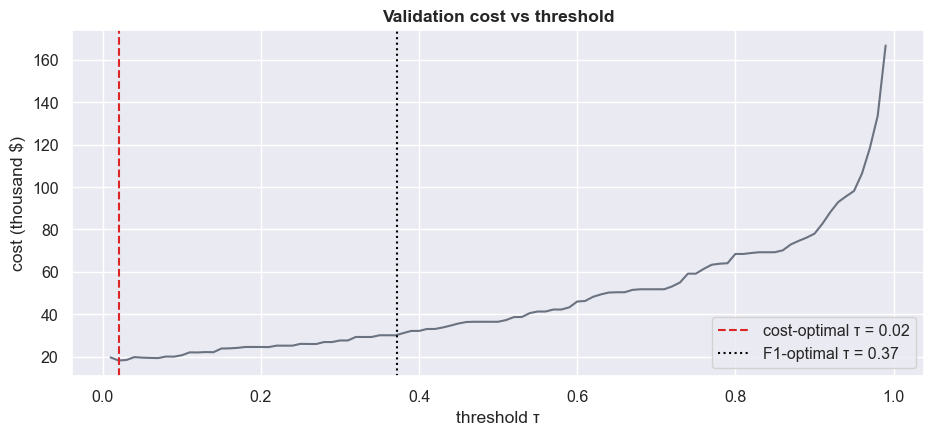

In [6]:
fig

**Answer:** the cost-optimal threshold ($\tau$ = 0.02) is far **lower** than the F1-optimal one (0.37): a missed fraud costs
hundreds of dollars, a review only \$10, so it pays to alert more often. On validation the cost falls from \$671,623
(no model) to \$30,047 (F1-optimal) and \$18,168 (cost-optimal). We use $\tau_{cost}$ for the final evaluation.

# [3/11] Final model: refit on train + valid
> **Objective:** <u>use</u> all data before the test period (Jan 2019 – Jun 2020) with the tuned hyperparameters,
> so the model has seen the most recent patterns. Number of trees = the early-stopping value found in notebook 04.

In [7]:
train_valid = pd.concat([train, valid], ignore_index=True)
final_model = lgb.LGBMClassifier(**BEST["params"]).fit(train_valid[FEATURES], train_valid[TARGET])
joblib.dump(final_model, MODELS_DIR / "lgbm_final.joblib")
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
test["proba"] = p_test
test["alert"] = (p_test >= tau_cost).astype(int)

In [8]:
print(f"trained on {len(train_valid):,} rows; test alerts: {test.alert.sum():,} of {len(test):,} transactions")

trained on 1,296,675 rows; test alerts: 2,665 of 555,719 transactions


# [4/11] Test performance
> **Question:** how well does the model work on six months of **future** data it has never seen?

In [9]:
y_test = test[TARGET]
test_metrics = pd.DataFrame([
    score(y_test, p_test, tau_cost, f"cost-optimal τ={tau_cost:.2f}"),
    score(y_test, p_test, tau_f1, f"F1-optimal τ={tau_f1:.2f}"),
]).set_index("model")
test_metrics["recall@90%prec"] = recall_at_precision(y_test, p_test, MIN_PRECISION)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
plot_pr_roc({"LightGBM (final)": p_test}, y_test, ax=axes[:2])
plot_confusion(y_test, p_test, tau_cost, ax=axes[2], title=f"Test confusion matrix @ τ={tau_cost:.2f}")
fig.tight_layout()
savefig(fig, "05_test_performance")
plt.close(fig)

In [10]:
test_metrics.round(4)

,pr_auc,roc_auc,precision,recall,f1,threshold,recall@90%prec
model,,,,,,,
cost-optimal τ=0.02,0.978,0.9995,0.7805,0.9697,0.8649,0.0200,0.9483
F1-optimal τ=0.37,0.978,0.9995,0.9753,0.9030,0.9378,0.3724,0.9483


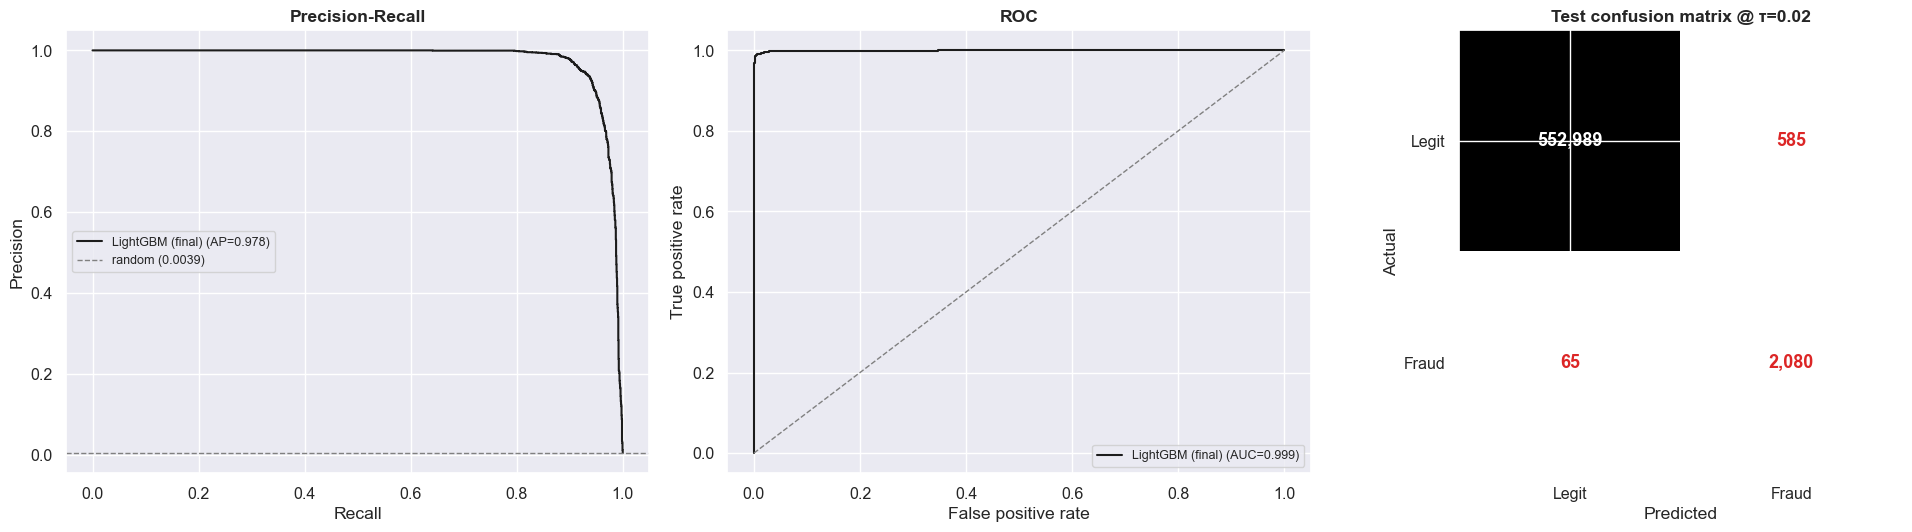

In [11]:
fig

# [5/11] Business impact in dollars
> **Question:** what does the model save on the test period?
>
> - **Fraud caught** $= \sum_{TP} \text{amount}$, **fraud missed** $= \sum_{FN} \text{amount}$
> - **Review cost** $= 10 \cdot \#\text{alerts}$
> - **Net saving** $=$ fraud caught $-$ review cost

In [12]:
fraud_amount = test.loc[y_test == 1, "amount"]
caught = test.loc[(y_test == 1) & (test.alert == 1), "amount"].sum()
missed = test.loc[(y_test == 1) & (test.alert == 0), "amount"].sum()
review = test.alert.sum() * REVIEW_COST
impact = pd.Series({
    "total fraud $": fraud_amount.sum(),
    "fraud caught $": caught,
    "fraud missed $": missed,
    "share of fraud $ caught": caught / fraud_amount.sum(),
    "alerts": test.alert.sum(),
    "alerts per day": test.alert.sum() / test.trans_time.dt.date.nunique(),
    "review cost $": review,
    "net saving $": caught - review,
})

In [13]:
impact.apply(lambda v: f"{v:,.2%}" if v < 1 else f"{v:,.0f}")

total fraud $              1,133,325
fraud caught $             1,120,075
fraud missed $                13,250
share of fraud $ caught       98.83%
alerts                         2,665
alerts per day                    14
review cost $                 26,650
net saving $               1,093,425
dtype: object

# [6/11] Calibration
> **Question:** when the model says "30 % fraud", is it fraud about 30 % of the time?
>
> **Brier score:** $\text{BS} = \frac{1}{n}\sum_i (\hat{p}_i - y_i)^2$ — lower is better.
> A reliability curve plots mean predicted probability vs observed fraud rate per bin; the diagonal is perfect calibration.

In [14]:
calibration = (pd.DataFrame({"predicted": p_test, "fraud": y_test.values})
               .groupby(pd.cut(p_test, CALIBRATION_BINS), observed=True)
               .agg(transactions=("fraud", "size"), mean_predicted=("predicted", "mean"), observed_rate=("fraud", "mean")))
brier = brier_score_loss(y_test, p_test)
brier_base = brier_score_loss(y_test, np.full(len(y_test), y_test.mean()))

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([1e-4, 1], [1e-4, 1], ls="--", c="grey", label="perfect")
plotted = calibration[calibration["observed_rate"] > 0]
ax.plot(plotted["mean_predicted"], plotted["observed_rate"], marker="o", color=COLORS[1], label="LightGBM")
ax.set(xscale="log", yscale="log", xlabel="mean predicted probability", ylabel="observed fraud rate",
       title="Reliability curve (test)")
ax.legend()
savefig(fig, "05_calibration")
plt.close(fig)

In [15]:
print(f"Brier score: {brier:.5f}  (always predicting the base rate: {brier_base:.5f})")
calibration.round(4)

Brier score: 0.00039  (always predicting the base rate: 0.00384)


,transactions,mean_predicted,observed_rate
"(0.0, 0.001]",549190,0.0000,0.0000
"(0.001, 0.01]",3515,0.0029,0.0077
"(0.01, 0.05]",661,0.0228,0.0741
"(0.05, 0.1]",158,0.0733,0.1899
"(0.1, 0.25]",151,0.1698,0.3907
"(0.25, 0.5]",113,0.3695,0.5398
"(0.5, 0.75]",89,0.6358,0.7978
"(0.75, 0.9]",100,0.8390,0.9200
"(0.9, 0.99]",335,0.9649,0.9910
"(0.99, 1.0]",1407,0.9986,0.9993


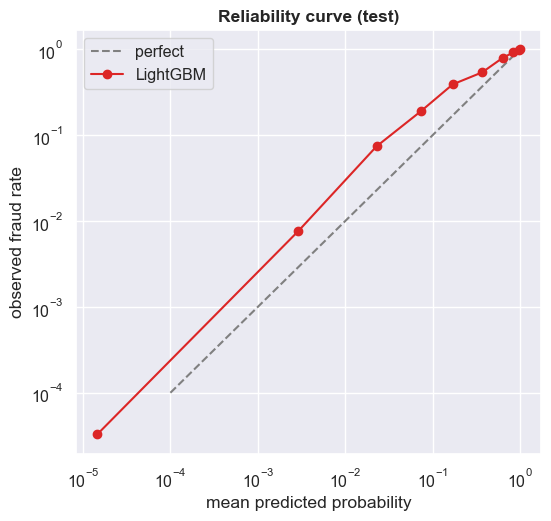

In [16]:
fig

**Answer:** only partly. At the extremes the model is reliable (above 0.9 predicted, 99 % or more are fraud; below 0.001, almost
none are), but in the middle it is **under-confident**: predicted 0.17 corresponds to an observed rate of 0.39, and 0.02 to 0.07.
Ranking is excellent, and the threshold was chosen on costs rather than by reading probabilities literally. If the score were
shown as a real likelihood, it should first be recalibrated (e.g. isotonic regression fitted on a held-out period).

# [7/11] Global explainability: feature importance & SHAP
> **Question:** which features drive the model overall?
>
> **SHAP (SHapley Additive exPlanations):** each prediction (in log-odds) is split into contributions
> $f(x) = \phi_0 + \sum_{j=1}^{M} \phi_j$, where $\phi_j$ is feature $j$'s Shapley value — its average marginal
> contribution over all orders in which features could be added. Unlike split-count importance, SHAP is consistent
> and shows **direction** (red = high feature value).

In [17]:
rng = np.random.default_rng(RANDOM_STATE)
fraud_rows = np.flatnonzero(y_test.values == 1)
legit_rows = rng.choice(np.flatnonzero(y_test.values == 0), SHAP_SAMPLE - len(fraud_rows), replace=False)
shap_rows = np.concatenate([fraud_rows, legit_rows])
X_shap = test.iloc[shap_rows][FEATURES]

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_shap)
gain = pd.Series(final_model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(0), index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(gain.index, gain.values / gain.sum(), color=COLORS[0])
axes[0].set(title="LightGBM importance (share of total gain)")
plt.sca(axes[1])
shap.plots.beeswarm(shap_values, max_display=19, show=False, plot_size=None)
axes[1].set_title("SHAP values (test sample, all frauds included)")
fig.tight_layout()
savefig(fig, "05_shap_summary")
plt.close(fig)

In [18]:
mean_abs_shap.round(3)

amount                 1.427
category               1.129
card_amount_sum_24h    0.935
card_txn_index         0.544
is_night               0.435
card_txn_count_24h     0.405
hour                   0.376
card_txn_count_7d      0.371
secs_since_prev_txn    0.346
card_amount_sum_7d     0.333
age                    0.333
amount_vs_card_mean    0.322
log_city_pop           0.306
log_amount             0.234
card_amount_sum_1h     0.173
day_of_week            0.121
is_male                0.100
distance_km            0.060
card_txn_count_1h      0.027
dtype: float64

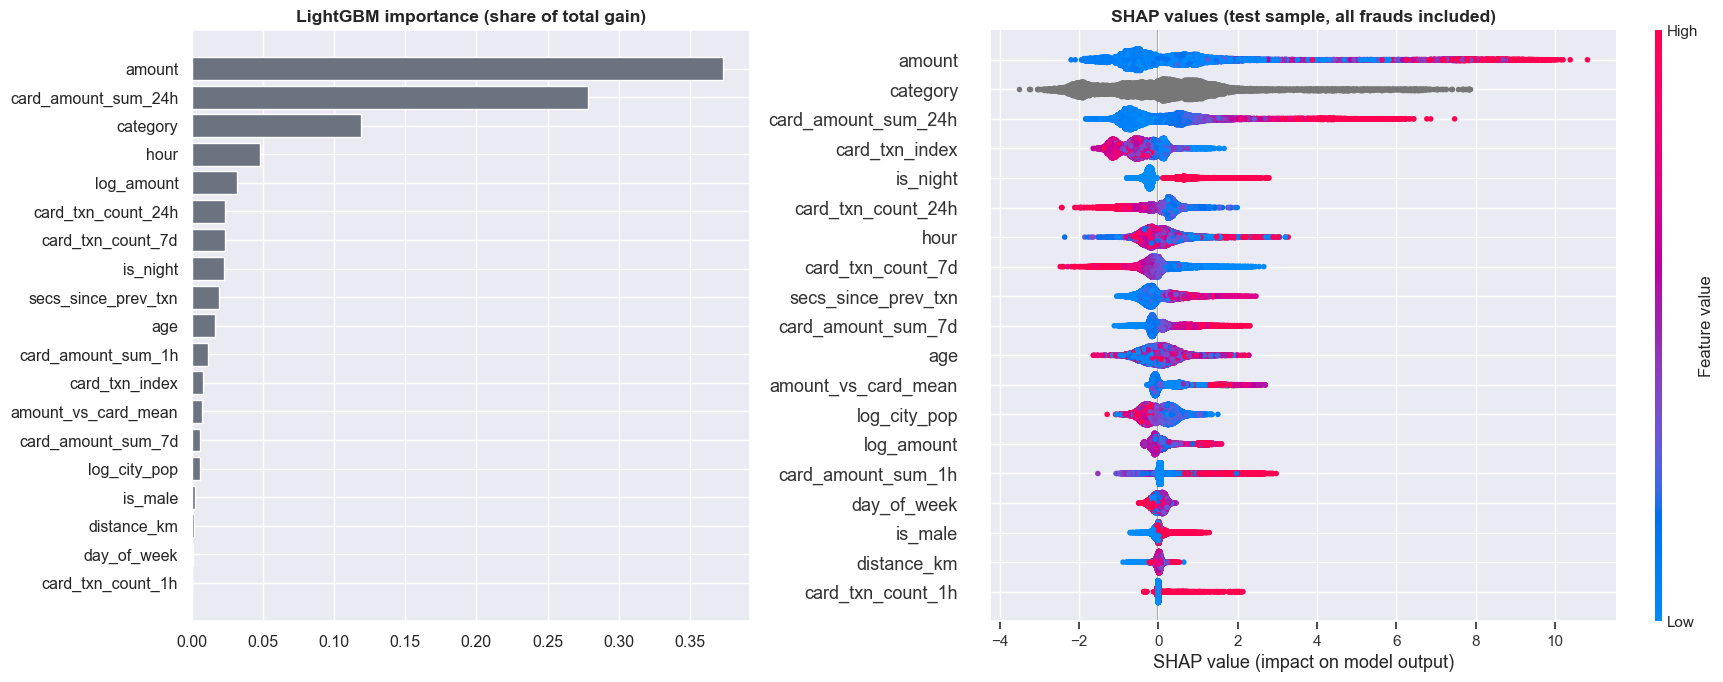

In [19]:
fig

## 7.1 Dependence: how do the top features act?
> **Objective:** <u>see</u> the shape of each top feature's effect (SHAP value vs feature value).

In [20]:
top4 = mean_abs_shap.index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, f in zip(axes, top4):
    shap.plots.scatter(shap_values[:, f], ax=ax, show=False, color=COLORS[0], alpha=0.3, dot_size=6)
    ax.axhline(0, c="black", lw=0.8)
    ax.set_title(f)
fig.tight_layout()
savefig(fig, "05_shap_dependence")
plt.close(fig)

In [21]:
top4

['amount', 'category', 'card_amount_sum_24h', 'card_txn_index']

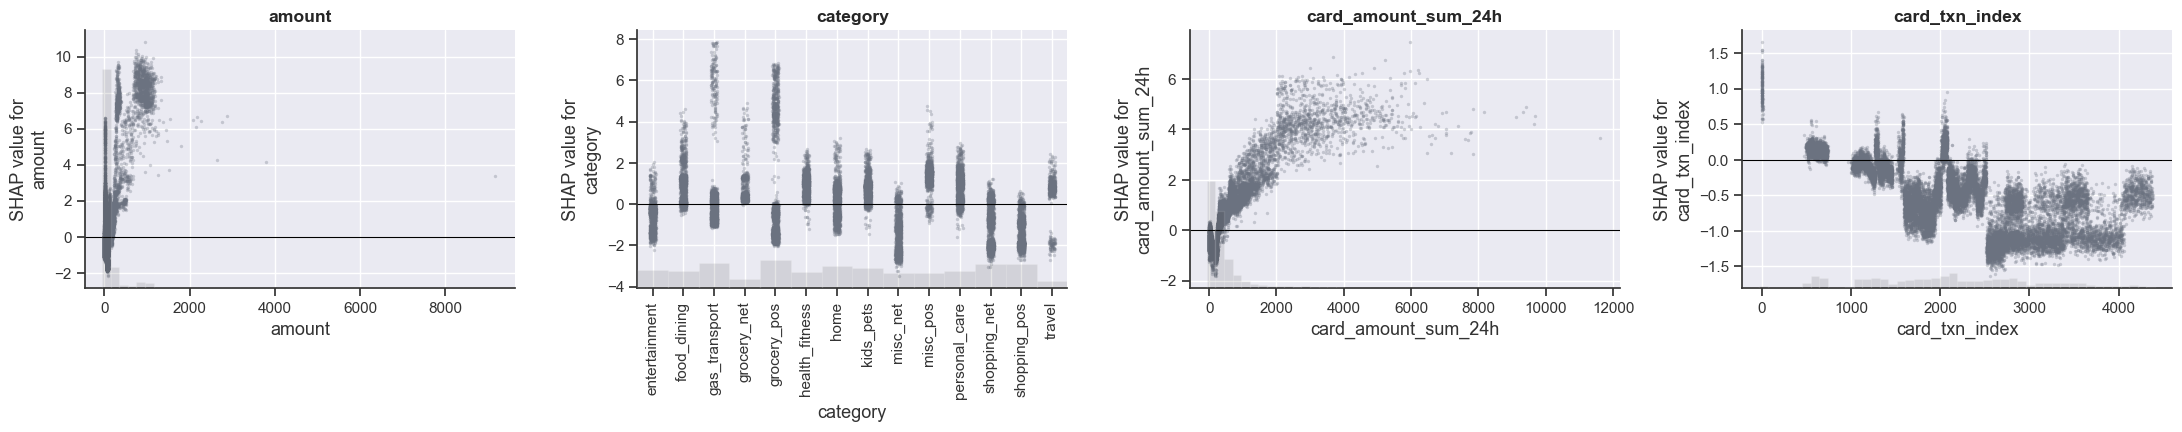

In [22]:
fig

# [8/11] Local explainability: why was this transaction flagged?
> **Objective:** <u>explain</u> single decisions — what an analyst would see next to an alert.
> The waterfall starts at the average log-odds $\phi_0$ and adds each feature's $\phi_j$ to reach this transaction's score.

In [23]:
shap_df = test.iloc[shap_rows].reset_index(drop=True)
caught_i = shap_df.index[(shap_df[TARGET] == 1) & (shap_df.alert == 1)][0]
missed_candidates = shap_df.index[(shap_df[TARGET] == 1) & (shap_df.alert == 0)]
missed_i = missed_candidates[0] if len(missed_candidates) else None

fig = plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[caught_i], max_display=10, show=False)
plt.title("Caught fraud", loc="left")
savefig(plt.gcf(), "05_shap_waterfall_caught")
fig_caught = plt.gcf()
plt.close(fig_caught)

In [24]:
shap_df.loc[caught_i, ["trans_time", "category", "amount", "hour", "card_amount_sum_24h", "amount_vs_card_mean", "proba"]]

trans_time             2020-06-21 22:06:39
category                    health_fitness
amount                               24.84
hour                                    22
card_amount_sum_24h            1935.189941
amount_vs_card_mean               0.395265
proba                             0.746694
Name: 0, dtype: object

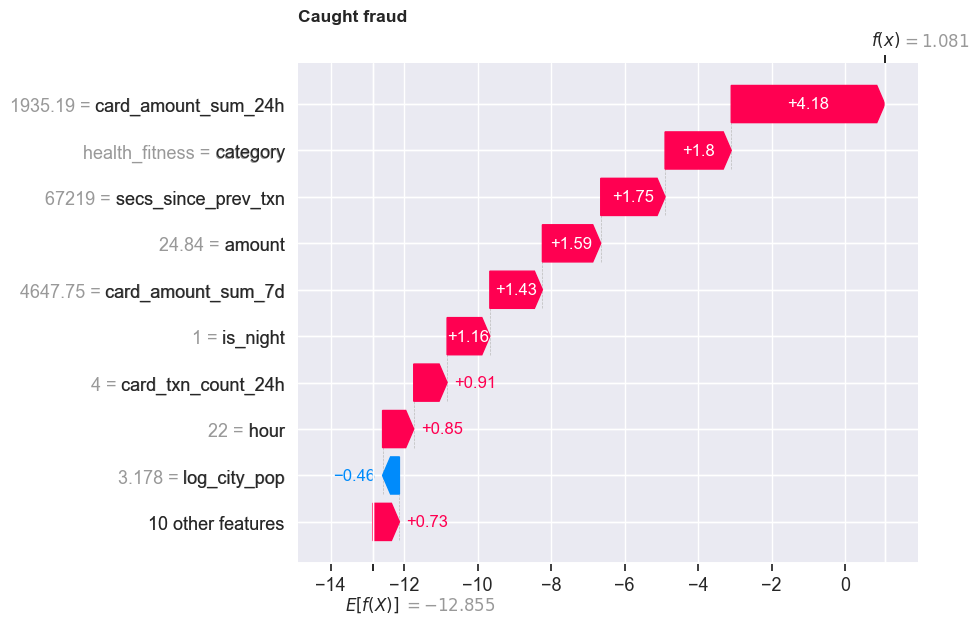

In [25]:
fig_caught

In [26]:
if missed_i is not None:
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_values[missed_i], max_display=10, show=False)
    plt.title("Missed fraud", loc="left")
    savefig(plt.gcf(), "05_shap_waterfall_missed")
    fig_missed = plt.gcf()
    plt.close(fig_missed)

In [27]:
shap_df.loc[missed_i, ["trans_time", "category", "amount", "hour", "card_amount_sum_24h", "amount_vs_card_mean", "proba"]]

trans_time             2020-06-24 22:26:26
category                     personal_care
amount                               46.36
hour                                    22
card_amount_sum_24h              20.969999
amount_vs_card_mean               0.777511
proba                              0.00118
Name: 29, dtype: object

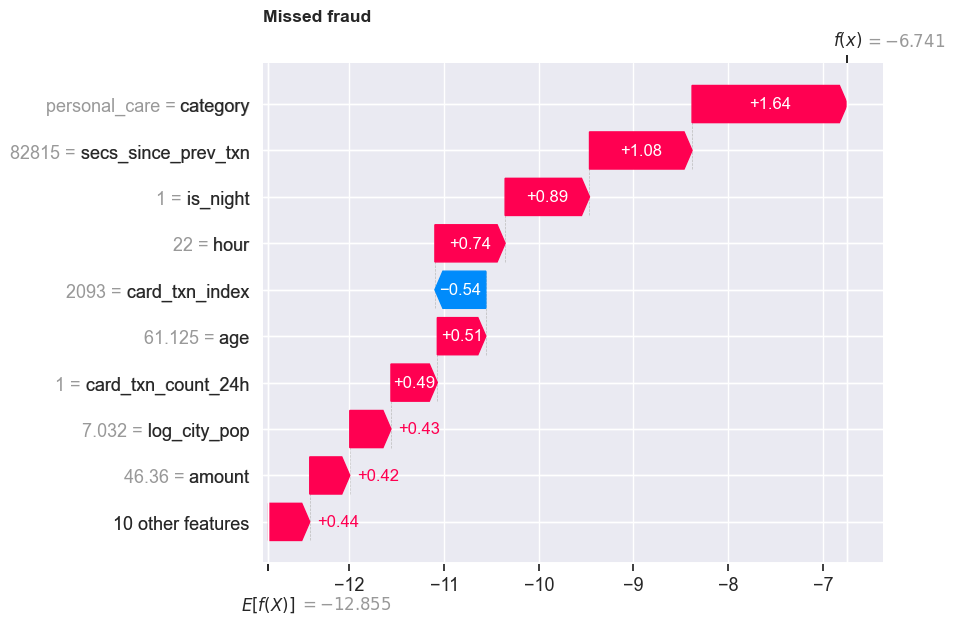

In [28]:
fig_missed

**Answer:** the caught fraud is only \$24.84, yet the model flags it (score 0.75) mostly because the card spent \$1,935 in the
previous 24 hours, plus category and night time. **The amount alone would never have caught it; card history did.**
The missed fraud (\$46.36 at 22:00) gets a score of 0.001: the amount is small and the card spent only about \$21 in the
previous 24 hours, so there is little to distinguish it from normal spending.

# [9/11] Error analysis
> **Question:** which fraud does the model miss, and where do false alarms come from?

In [29]:
test["outcome"] = np.select(
    [(y_test == 1) & (test.alert == 1), (y_test == 1) & (test.alert == 0), (y_test == 0) & (test.alert == 1)],
    ["TP (caught)", "FN (missed)", "FP (false alarm)"], "TN")
test["amount_band"] = pd.cut(test["amount"], AMOUNT_BINS)
fraud_test = test[y_test == 1]
recall_by_band = fraud_test.groupby("amount_band", observed=True)["alert"].agg(["size", "mean"]).rename(
    columns={"size": "frauds", "mean": "recall"})
recall_by_cat = fraud_test.groupby("category", observed=True)["alert"].agg(["size", "mean"]).rename(
    columns={"size": "frauds", "mean": "recall"}).sort_values("recall")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
axes[0].bar(recall_by_band.index.astype(str), recall_by_band["recall"], color=COLORS[1])
axes[0].set(title="Recall by amount band (test)", ylabel="share of fraud caught", ylim=(0, 1.05))
axes[0].tick_params(axis="x", rotation=30)
axes[1].barh(recall_by_cat.index.astype(str), recall_by_cat["recall"], color=COLORS[1])
axes[1].set(title="Recall by category (test)", xlabel="share of fraud caught", xlim=(0, 1.05))
fig.tight_layout()
savefig(fig, "05_error_analysis")
plt.close(fig)

In [30]:
recall_by_band.round(3)

,frauds,recall
amount_band,,
"(0, 50]",462,0.922
"(50, 200]",72,0.806
"(200, 500]",575,0.993
"(500, 800]",243,0.992
"(800, 1000]",517,0.990
"(1000, 1500]",276,0.986


In [31]:
test.groupby("outcome")[["amount", "hour", "card_amount_sum_24h", "amount_vs_card_mean"]].median().round(1)

,amount,hour,card_amount_sum_24h,amount_vs_card_mean
outcome,,,,
FN (missed),21.7,20.0,134.600006,0.4
FP (false alarm),82.5,17.0,866.700012,1.1
TN,47.1,14.0,210.699997,0.7
TP (caught),433.1,22.0,1851.599976,5.6


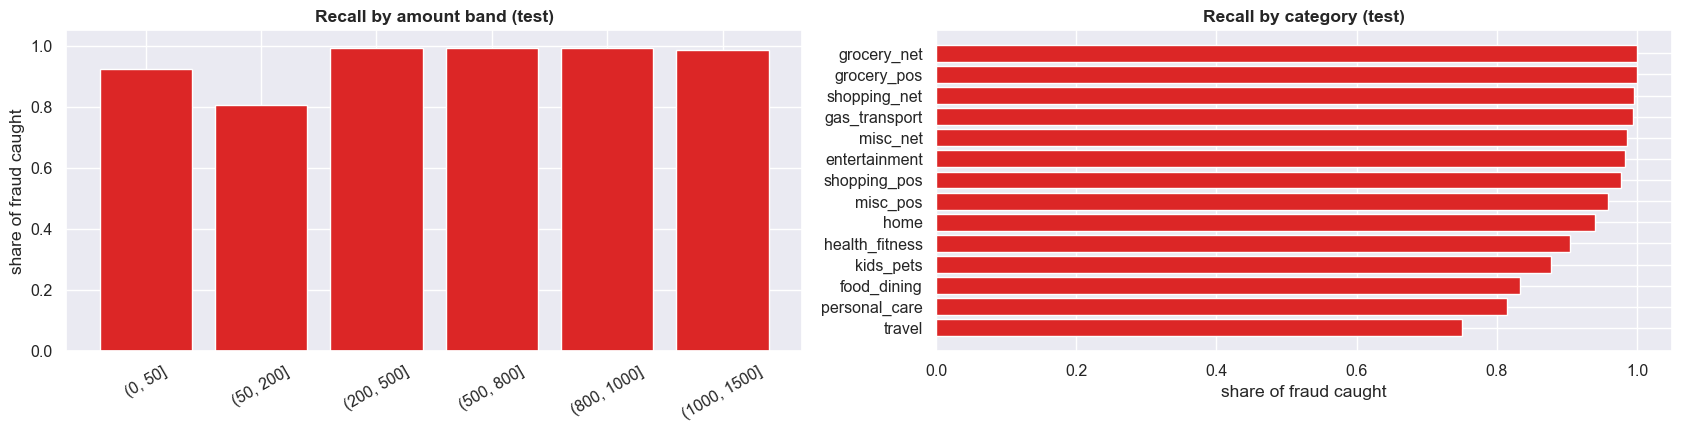

In [32]:
fig

**Answer:** recall is at least 98.6 % in every band above \$200. The 65 missed frauds are concentrated in **small amounts**:
50 of them are under \$200 (recall 92 % for \$0–50, 81 % for \$50–200), with a median of \$21.7. These look like normal
purchases and cost little individually, so the model still catches 98.8 % of fraud dollars. A production system could review
a card's recent small charges once a larger fraud is confirmed.

# [10/11] Stability over time
> **Question:** does performance degrade as we move further from the training period (concept drift)?

In [33]:
monthly = test.groupby(test.trans_time.dt.to_period("M")).apply(
    lambda g: pd.Series({"transactions": len(g), "frauds": g[TARGET].sum(),
                         "pr_auc": average_precision_score(g[TARGET], g.proba),
                         "recall": g.loc[g[TARGET] == 1, "alert"].mean(),
                         "precision": g.loc[g.alert == 1, TARGET].mean()}))

fig, ax = plt.subplots(figsize=(11, 4.5))
for col, c, m in [("pr_auc", COLORS[1], "o"), ("recall", "black", "s"), ("precision", COLORS[0], "^")]:
    ax.plot(monthly.index.astype(str), monthly[col], marker=m, color=c, label=col)
ax.set(ylim=(0, 1.05), title="Monthly performance on the test period", ylabel="score")
ax.legend()
savefig(fig, "05_stability")
plt.close(fig)

In [34]:
monthly.round(3)

,transactions,frauds,pr_auc,recall,precision
trans_time,,,,,
2020-06,30058.0,133.0,0.983,0.970,0.750
2020-07,85848.0,321.0,0.970,0.963,0.771
2020-08,88759.0,415.0,0.982,0.976,0.823
2020-09,69533.0,340.0,0.982,0.962,0.813
2020-10,69348.0,384.0,0.985,0.974,0.818
2020-11,72635.0,294.0,0.980,0.983,0.794
2020-12,139538.0,258.0,0.960,0.957,0.655


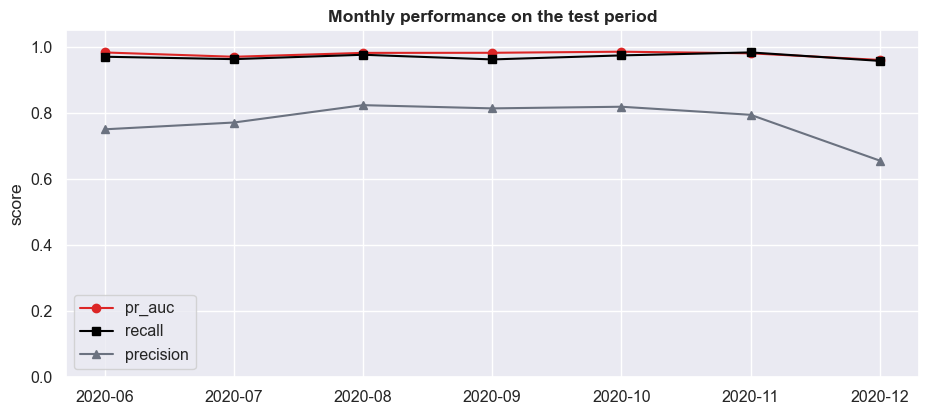

In [35]:
fig

**Answer:** PR-AUC (0.960–0.985) and recall (0.957–0.983) stay in a narrow band → no strong drift. Precision is more sensitive:
0.75–0.82 for most months, falling to **0.66 in December**, which has the most transactions and the lowest fraud rate
(0.18 %), so legitimate holiday spending triggers more false alarms. In production the threshold should be monitored over such periods.

# [11/11] Summary

In [36]:
summary = {
    "test_pr_auc": float(average_precision_score(y_test, p_test)),
    "test_roc_auc": float(test_metrics.iloc[0]["roc_auc"]),
    "threshold": float(tau_cost),
    "precision": float(test_metrics.iloc[0]["precision"]),
    "recall": float(test_metrics.iloc[0]["recall"]),
    "f1": float(test_metrics.iloc[0]["f1"]),
    "recall_at_90_precision": float(test_metrics.iloc[0]["recall@90%prec"]),
    "fraud_dollars_caught_share": float(caught / fraud_amount.sum()),
    "net_saving_dollars": float(caught - review),
    "brier": float(brier),
}
json.dump(summary, open(REPORTS_DIR / "test_metrics.json", "w"), indent=2)

In [37]:
pd.Series(summary).round(4)

test_pr_auc                   9.780000e-01
test_roc_auc                  9.995000e-01
threshold                     2.000000e-02
precision                     7.805000e-01
recall                        9.697000e-01
f1                            8.649000e-01
recall_at_90_precision        9.483000e-01
fraud_dollars_caught_share    9.883000e-01
net_saving_dollars            1.093425e+06
brier                         4.000000e-04
dtype: float64

- The final LightGBM, refit on Jan 2019 – Jun 2020, is evaluated **once** on Jun – Dec 2020: **PR-AUC 0.978**, recall 0.970,
  precision 0.781 at the cost-optimal threshold, catching **98.8 % of fraud dollars** with about 14 alerts per day.
- Threshold chosen by **dollar cost** on validation (\$10 per review vs the fraud amount when missed).
- **Calibration:** reliable at the extremes, under-confident in the middle; ranking is what the decision relies on.
- **SHAP:** `amount`, `category`, `card_amount_sum_24h`, `card_txn_index` and `is_night` drive the decisions. `card_txn_index` may
  reflect how the simulator generates data, so it should be re-checked before trusting it on real transactions.
- **Errors:** 50 of the 65 missed frauds are under \$200; recall is at least 98.6 % above \$200.
- **Stability:** PR-AUC and recall hold across the test months; precision dips in December.

(!) **Limitation:** this is **simulated** data with regular fraud patterns, so these scores are far higher than a real fraud system
would achieve. The value of this project is the leak-free method, not the headline number.